In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
!pip install segmentation-models-pytorch==0.3.3
!pip install albumentations==1.4.4
!pip install opencv-python-headless tifffile


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 13.1 MB/s  0:00:00
  Created wheel for efficientnet-pytorch: filename=efficientnet_pytorch-0.7.1-py3-none-any.whl size=16478 sha256=899c29b3140d621d7045fdd4615c9406d1af74bd9d846556d747dda167aa1cf4
  Stored in directory: /root/.cache/pip/wheels/5b/2f/2c/f72934c756bb8333dc80c448b1c97e40665b27b7fd15d6be9f
  Created wheel for pretrainedmodels: filename=pretrainedmodels-0.7.4-py3-none-any.whl size=60991 sha256=b3df81c5f4f3693b0704c0ca8edb966f7473187fff8acbbbf9f965f9ddecaac5
  Stored in directory: /root/.cache/pip/wheels/49/bb/ce/d5f112de8a91a1c30aa828da96bcf99504398229bac87d829c
Successfully built efficientnet-pytorch pretrainedmodels
  Attempting uninstall: timm
    Foun

In [4]:
import torch
import segmentation_models_pytorch as smp

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
)

print(model)

Downloading: "https://download.pytorch.org/models/resnet34-333f7ec4.pth" to /root/.cache/torch/hub/checkpoints/resnet34-333f7ec4.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 229MB/s]


Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

In [5]:
import torch
import segmentation_models_pytorch as smp

device = "cuda" if torch.cuda.is_available() else "cpu"

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

# Simulate one RGB aerial image (batch=1, 256x256)
x = torch.randn(1, 3, 256, 256).to(device)

with torch.no_grad():
    output = model(x)

print("Device:", device)
print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("GPU allocated:", round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

Device: cuda
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])
GPU allocated: 95.52 MB


In [45]:
from pathlib import Path
from collections import defaultdict

DATA_ROOT = Path("/content/dataset/cropped_1024_padding")

city_data = defaultdict(lambda: {"images": 0, "masks": 0})

for tile_dir in DATA_ROOT.iterdir():
    if not tile_dir.is_dir():
        continue

    city = tile_dir.name.rstrip("0123456789")

    image_dir = tile_dir / "images"
    mask_dir = tile_dir / "binary_masks"

    city_data[city]["images"] += len(
        list(image_dir.glob("*.jpg"))
    )
    city_data[city]["masks"] += len(
        list(mask_dir.glob("*.tif"))
    )

for city, counts in sorted(city_data.items()):
    print(
        f"{city:10s} | "
        f"Images: {counts['images']:4d} | "
        f"Masks: {counts['masks']:4d}"
    )

austin     | Images:  180 | Masks:  180
chicago    | Images:  180 | Masks:  180
kitsap     | Images:  180 | Masks:  180
tyrol-w    | Images:  180 | Masks:  180
vienna     | Images:  180 | Masks:  180


In [63]:
%%writefile src/data/dataset.py

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset
import albumentations as A


def get_train_transform(crop=512):
    return A.Compose([
        A.RandomCrop(height=crop, width=crop),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.RandomBrightnessContrast(p=0.2),
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        )
    ], additional_targets={"boundary": "mask"})


def get_val_transform(crop=512):
    return A.Compose([
        A.CenterCrop(height=crop, width=crop),
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        )
    ], additional_targets={"boundary": "mask"})


class InriaDataset(Dataset):

    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

        assert len(self.image_paths) == len(self.mask_paths), \
            "Image and mask counts do not match!"

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image_path = str(self.image_paths[idx])
        mask_path = str(self.mask_paths[idx])

        # Load RGB image
        image = cv2.imread(image_path)

        if image is None:
            raise ValueError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Load grayscale binary mask
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if mask is None:
            raise ValueError(f"Cannot read mask: {mask_path}")

        mask = (mask > 127).astype(np.uint8)

        # Generate boundary ground truth
        kernel = np.ones((3, 3), dtype=np.uint8)

        boundary = cv2.morphologyEx(
            mask,
            cv2.MORPH_GRADIENT,
            kernel
        )

        boundary = (boundary > 0).astype(np.uint8)

        # Apply synchronized image/mask transformations
        if self.transform is not None:
            augmented = self.transform(
                image=image,
                mask=mask,
                boundary=boundary
            )

            image = augmented["image"]
            mask = augmented["mask"]
            boundary = augmented["boundary"]

        # Convert HWC -> CHW
        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        mask = torch.from_numpy(
            np.ascontiguousarray(mask)
        ).float().unsqueeze(0)

        boundary = torch.from_numpy(
            np.ascontiguousarray(boundary)
        ).float().unsqueeze(0)

        # Two target channels: building mask + boundary mask
        target = torch.cat([mask, boundary], dim=0)

        return image, target

Writing src/data/dataset.py


In [64]:
%%writefile src/data/splits.py

from pathlib import Path
import re


TRAIN_CITIES = {"austin", "chicago", "kitsap", "tyrol-w"}
VAL_CITIES = {"vienna"}


def get_city_name(tile_name):
    return re.sub(r"\d+$", "", tile_name.lower())


def create_splits(data_root):

    data_root = Path(data_root)

    train_images = []
    train_masks = []

    val_images = []
    val_masks = []

    unmatched = []

    for tile_dir in sorted(data_root.iterdir()):

        if not tile_dir.is_dir():
            continue

        city = get_city_name(tile_dir.name)

        if city not in TRAIN_CITIES and city not in VAL_CITIES:
            continue

        image_dir = tile_dir / "images"
        mask_dir = tile_dir / "binary_masks"

        for image_path in sorted(image_dir.glob("*.jpg")):

            mask_path = mask_dir / f"{image_path.stem}.tif"

            if not mask_path.exists():
                unmatched.append(str(image_path))
                continue

            if city in TRAIN_CITIES:
                train_images.append(image_path)
                train_masks.append(mask_path)

            elif city in VAL_CITIES:
                val_images.append(image_path)
                val_masks.append(mask_path)

    print("Dataset split completed")
    print("------------------------")
    print("Training samples:", len(train_images))
    print("Validation samples:", len(val_images))
    print("Unmatched images:", len(unmatched))

    if unmatched:
        print("First unmatched image:", unmatched[0])

    return train_images, train_masks, val_images, val_masks

Writing src/data/splits.py


In [65]:
from src.data.dataset import (
    InriaDataset,
    get_train_transform,
    get_val_transform
)

from src.data.splits import create_splits

DATA_ROOT = "/content/dataset/cropped_1024_padding"

train_images, train_masks, val_images, val_masks = create_splits(DATA_ROOT)

train_dataset = InriaDataset(
    train_images,
    train_masks,
    transform=get_train_transform(crop=512)
)

val_dataset = InriaDataset(
    val_images,
    val_masks,
    transform=get_val_transform(crop=512)
)

print("\nDataset lengths:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

# Inspect one training sample
image, target = train_dataset[0]

print("\nSample tensors:")
print("Image:", image.shape)
print("Target:", target.shape)
print("Mask values:", torch.unique(target[0]))
print("Boundary values:", torch.unique(target[1]))

Dataset split completed
------------------------
Training samples: 720
Validation samples: 180
Unmatched images: 0

Dataset lengths:
Train: 720
Validation: 180

Sample tensors:
Image: torch.Size([3, 512, 512])
Target: torch.Size([2, 512, 512])
Mask values: tensor([0., 1.])
Boundary values: tensor([0., 1.])


In [66]:
import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Inspect one batch
images, targets = next(iter(train_loader))

print("Images:", images.shape)
print("Targets:", targets.shape)

print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Images: torch.Size([2, 3, 512, 512])
Targets: torch.Size([2, 2, 512, 512])
GPU available: True
GPU: Tesla T4


In [67]:
from src.models.model import build_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = build_model().to(device)

images, targets = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Target shape:", targets.shape)

print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

Input shape: torch.Size([2, 3, 512, 512])
Output shape: torch.Size([2, 2, 512, 512])
Target shape: torch.Size([2, 2, 512, 512])
GPU memory allocated: 200.03 MB


In [68]:
import torch
import torch.nn as nn

class DiceBCELoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.smooth = smooth

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)

        intersection = (probs * targets).sum(dim=(1, 2, 3))
        denominator = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

        dice = (2 * intersection + self.smooth) / (
            denominator + self.smooth
        )

        dice_loss = 1 - dice.mean()

        return dice_loss + bce_loss


class MaskBoundaryLoss(nn.Module):
    def __init__(self, boundary_weight=2.0):
        super().__init__()
        self.mask_loss = DiceBCELoss()
        self.boundary_loss = nn.BCEWithLogitsLoss()
        self.boundary_weight = boundary_weight

    def forward(self, logits, targets):
        mask_logits = logits[:, 0:1]
        boundary_logits = logits[:, 1:2]

        mask_targets = targets[:, 0:1]
        boundary_targets = targets[:, 1:2]

        loss_mask = self.mask_loss(mask_logits, mask_targets)
        loss_boundary = self.boundary_loss(
            boundary_logits, boundary_targets
        )

        total_loss = (
            loss_mask + self.boundary_weight * loss_boundary
        )

        return total_loss

In [69]:
import torch
import torch.optim as optim
from tqdm.auto import tqdm
import os

device = torch.device("cuda")

model = build_model().to(device)

criterion = MaskBoundaryLoss(boundary_weight=2.0)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler("cuda")

EPOCHS = 5
BEST_VAL_LOSS = float("inf")

CHECKPOINT_DIR = "/content/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Training initialized.")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Device:", device)

Training initialized.
Parameters: 24436514
Device: cuda


In [70]:
def train_one_epoch(model, loader, criterion, optimizer, scaler):

    model.train()
    running_loss = 0.0

    progress = tqdm(loader, desc="Training")

    for images, targets in progress:

        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    return running_loss / len(loader)


@torch.no_grad()
def validate(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_intersection = 0.0
    total_union = 0.0

    for images, targets in tqdm(loader, desc="Validation"):

        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, targets)

        total_loss += loss.item()

        # Evaluate only the building segmentation channel
        predictions = torch.sigmoid(outputs[:, 0:1]) > 0.5
        actual = targets[:, 0:1] > 0.5

        total_intersection += (predictions & actual).sum().item()
        total_union += (predictions | actual).sum().item()

    val_loss = total_loss / len(loader)

    iou = total_intersection / (total_union + 1e-7)
    dice = (2 * iou) / (1 + iou + 1e-7)

    return val_loss, iou, dice

In [71]:
history = {
    "train_loss": [],
    "val_loss": [],
    "val_iou": [],
    "val_dice": []
}

for epoch in range(EPOCHS):

    print(f"\n{'='*50}")
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"{'='*50}")

    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler
    )

    val_loss, val_iou, val_dice = validate(
        model, val_loader, criterion
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["val_dice"].append(val_dice)

    print(f"\nTrain Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation IoU: {val_iou:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")

    if val_loss < BEST_VAL_LOSS:

        BEST_VAL_LOSS = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "val_iou": val_iou,
            "val_dice": val_dice
        }, f"{CHECKPOINT_DIR}/best_model_boundary.pth")

        print("Best checkpoint saved!")

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history
    }, f"{CHECKPOINT_DIR}/latest_model_boundary.pth")

print("\nTraining completed.")


Epoch 1/5


Training:   0%|          | 0/360 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]


Train Loss: 2.0441
Validation Loss: 1.3980
Validation IoU: 0.5615
Validation Dice: 0.7192
Best checkpoint saved!

Epoch 2/5


Training:   0%|          | 0/360 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

... (6 outputs left out)


Train Loss: 0.9093
Validation Loss: 1.0311
Validation IoU: 0.5960
Validation Dice: 0.7468
Best checkpoint saved!

Epoch 5/5


Training:   0%|          | 0/360 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]


Train Loss: 0.8604
Validation Loss: 0.9592
Validation IoU: 0.6402
Validation Dice: 0.7807
Best checkpoint saved!

Training completed.


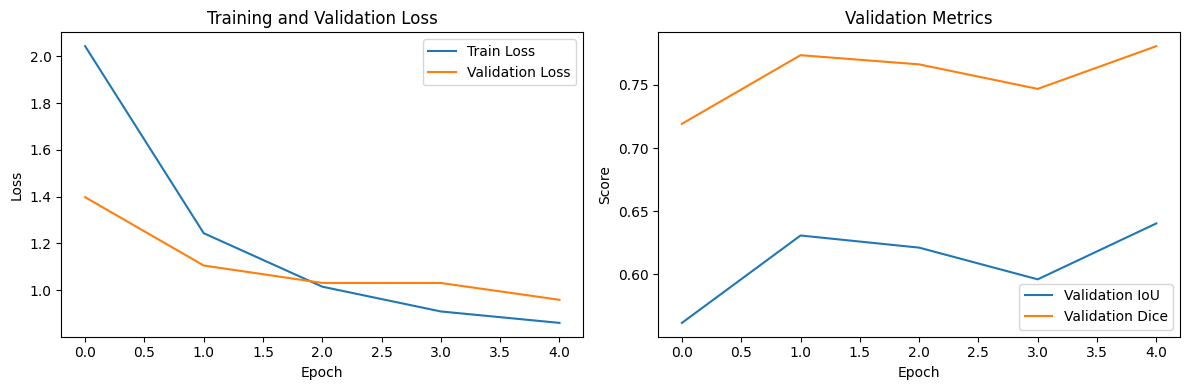

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["val_iou"], label="Validation IoU")
plt.plot(history["val_dice"], label="Validation Dice")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Metrics")
plt.legend()

plt.tight_layout()
plt.show()

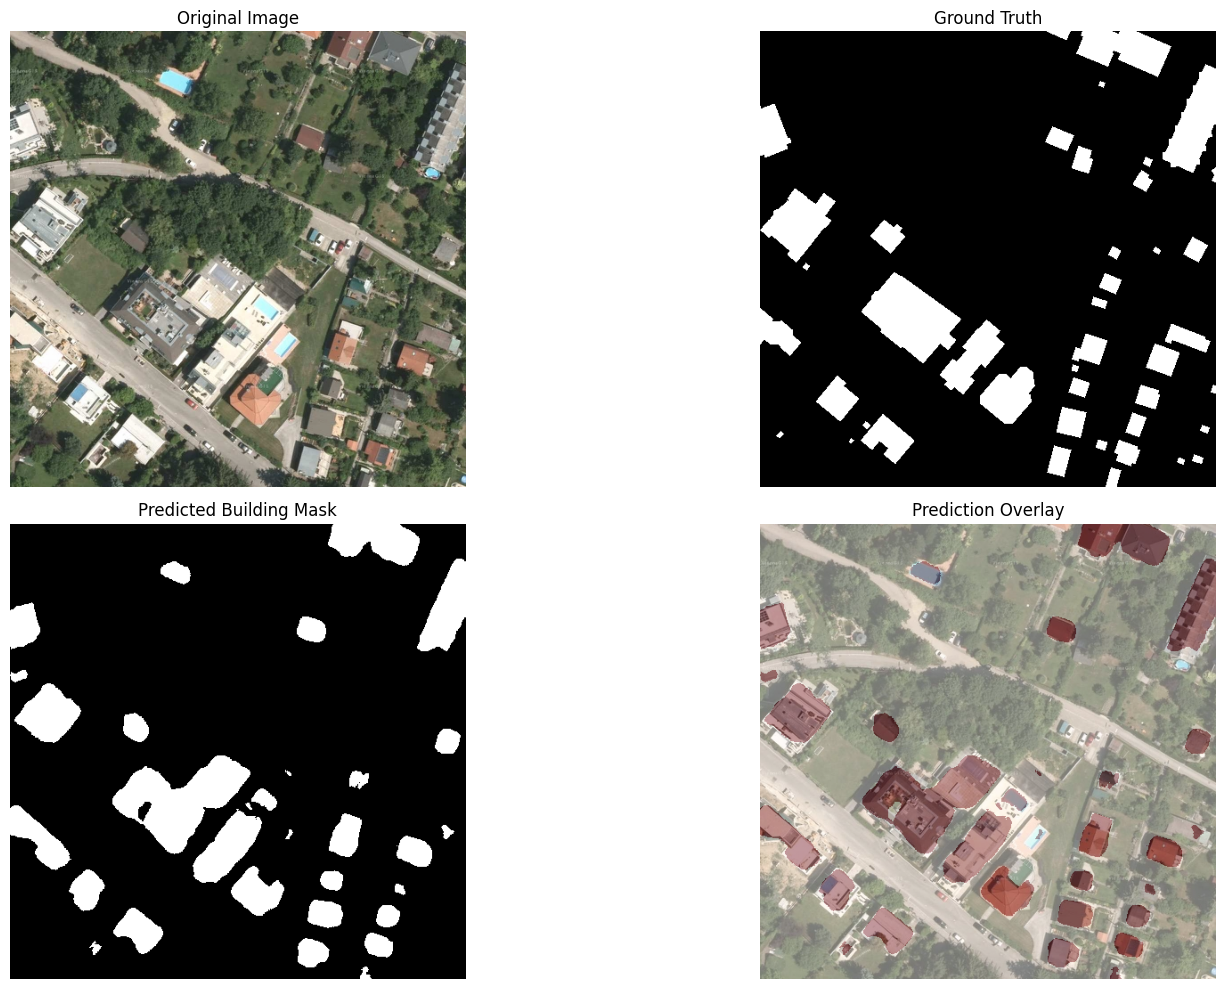

In [73]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

# Select a validation sample
image, target = val_dataset[0]

with torch.no_grad():
    input_tensor = image.unsqueeze(0).to(device)

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        output = model(input_tensor)

    # Building prediction
    pred = torch.sigmoid(output[:, 0:1])[0, 0]
    pred = (pred > 0.5).cpu().numpy()

    # Boundary prediction
    boundary_pred = torch.sigmoid(output[:, 1:2])[0, 0]
    boundary_pred = (boundary_pred > 0.5).cpu().numpy()

# Ground truth
ground_truth = target[0].numpy()

# Reverse ImageNet normalization
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

display_image = image.permute(1, 2, 0).numpy()
display_image = display_image * std + mean
display_image = np.clip(display_image, 0, 1)

plt.figure(figsize=(18, 10))

plt.subplot(2, 2, 1)
plt.imshow(display_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(ground_truth, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(pred, cmap="gray")
plt.title("Predicted Building Mask")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(display_image)
plt.imshow(pred, cmap="Reds", alpha=0.4)
plt.title("Prediction Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [74]:
import torch

latest_path = "/content/checkpoints/latest_model_boundary.pth"

checkpoint = torch.load(
    latest_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

start_epoch = checkpoint["epoch"]

history = checkpoint["history"]

print("Resuming from epoch:", start_epoch)
print("Previous training history:", history)

Resuming from epoch: 5
Previous training history: {'train_loss': [2.0440550727976694, 1.2440875968999332, 1.0153125092387199, 0.9092697424193223, 0.8604206360876561], 'val_loss': [1.3980174276563857, 1.105891970793406, 1.031362544827991, 1.0311067197057935, 0.9591671168804169], 'val_iou': [0.5614649647802867, 0.6306900544358974, 0.6210833827880566, 0.5959623026880109, 0.6402417410682482], 'val_dice': [0.7191514910508616, 0.7735253110105043, 0.7662571229457874, 0.7468375215910565, 0.7806674906564691]}


In [75]:
TOTAL_EPOCHS = 20

for epoch in range(start_epoch, TOTAL_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{TOTAL_EPOCHS}")

    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler
    )

    val_loss, val_iou, val_dice = validate(
        model, val_loader, criterion
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["val_dice"].append(val_dice)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss:   {val_loss:.4f}")
    print(f"Val IoU:    {val_iou:.4f}")
    print(f"Val Dice:   {val_dice:.4f}")

    if val_loss < BEST_VAL_LOSS:

        BEST_VAL_LOSS = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "val_iou": val_iou,
            "val_dice": val_dice
        }, "/content/checkpoints/best_model_boundary.pth")

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history
    }, latest_path)


Epoch 6/20


Training:   0%|          | 0/360 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe21598dd00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe21598dd00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Train Loss: 0.8255
Val Loss:   0.9435
Val IoU:    0.6566
Val Dice:   0.7927

Epoch 7/20


Training:   0%|          | 0/360 [00:00<?, ?it/s]

... (37 outputs left out)

Train Loss: 0.6719
Val Loss:   0.8904
Val IoU:    0.6863
Val Dice:   0.8140

Epoch 20/20


Training:   0%|          | 0/360 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

Train Loss: 0.6382
Val Loss:   0.9188
Val IoU:    0.6621
Val Dice:   0.7967


In [76]:
import os

checkpoint_path = "/content/checkpoints/best_model_boundary.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
    print("Best epoch:", checkpoint["epoch"])
    print("Validation IoU:", checkpoint["val_iou"])

Checkpoint exists: True
Best epoch: 19
Validation IoU: 0.6863449431867517


In [77]:
checkpoint = torch.load(
    "/content/checkpoints/best_model_boundary.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["epoch"])

Loaded best checkpoint from epoch: 19


In [78]:
import numpy as np
import torch

@torch.no_grad()
def predict_full_image(model, image, patch_size=512, stride=384):

    model.eval()

    H, W, _ = image.shape

    probability_sum = np.zeros((H, W), dtype=np.float32)
    count_map = np.zeros((H, W), dtype=np.float32)

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    y_positions = list(range(0, H - patch_size + 1, stride))
    x_positions = list(range(0, W - patch_size + 1, stride))

    # Ensure the final row and column are covered
    if y_positions[-1] != H - patch_size:
        y_positions.append(H - patch_size)

    if x_positions[-1] != W - patch_size:
        x_positions.append(W - patch_size)

    for y in y_positions:
        for x in x_positions:

            patch = image[
                y:y + patch_size,
                x:x + patch_size
            ].astype(np.float32) / 255.0

            patch = (patch - mean) / std

            patch = torch.from_numpy(
                patch.transpose(2, 0, 1).copy()
            ).float().unsqueeze(0).to(device)

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                output = model(patch)

            # Only the building segmentation channel
            probability = torch.sigmoid(output[:, 0:1])

            probability = probability[0, 0].float().cpu().numpy()

            probability_sum[
                y:y + patch_size,
                x:x + patch_size
            ] += probability

            count_map[
                y:y + patch_size,
                x:x + patch_size
            ] += 1

    return probability_sum / np.maximum(count_map, 1)

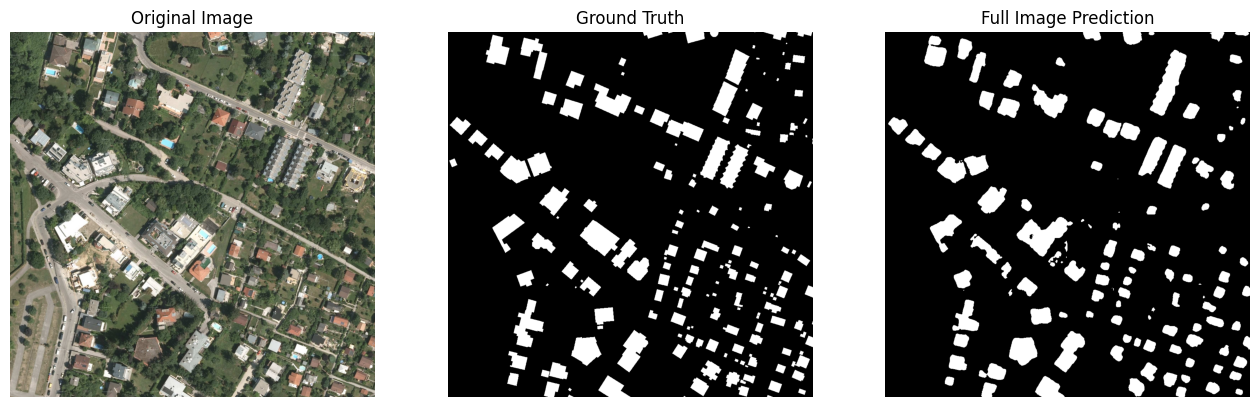

In [79]:
import cv2
import matplotlib.pyplot as plt

image_path = val_images[0]
mask_path = val_masks[0]

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

ground_truth = cv2.imread(
    str(mask_path),
    cv2.IMREAD_GRAYSCALE
)

ground_truth = (ground_truth > 127).astype(np.uint8)

probability = predict_full_image(model, image)

prediction = (probability > 0.5).astype(np.uint8)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ground_truth, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, cmap="gray")
plt.title("Full Image Prediction")
plt.axis("off")

plt.show()

In [80]:
intersection = np.logical_and(
    prediction == 1,
    ground_truth == 1
).sum()

union = np.logical_or(
    prediction == 1,
    ground_truth == 1
).sum()

tp = intersection
fp = np.logical_and(
    prediction == 1,
    ground_truth == 0
).sum()

fn = np.logical_and(
    prediction == 0,
    ground_truth == 1
).sum()

iou = tp / (union + 1e-7)
dice = 2 * tp / (2 * tp + fp + fn + 1e-7)
precision = tp / (tp + fp + 1e-7)
recall = tp / (tp + fn + 1e-7)

print(f"IoU:       {iou:.4f}")
print(f"Dice:      {dice:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")

IoU:       0.7229
Dice:      0.8392
Precision: 0.8512
Recall:    0.8274


In [81]:
from tqdm.auto import tqdm
import numpy as np
import time

total_tp = 0
total_fp = 0
total_fn = 0

start_time = time.time()

for image_path, mask_path in tqdm(
    zip(val_images, val_masks),
    total=len(val_images)
):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    gt = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    gt = (gt > 127)

    probabilities = predict_full_image(model, image)
    pred = probabilities > 0.5

    total_tp += np.logical_and(pred, gt).sum()
    total_fp += np.logical_and(pred, ~gt).sum()
    total_fn += np.logical_and(~pred, gt).sum()

elapsed = time.time() - start_time

iou = total_tp / (total_tp + total_fp + total_fn + 1e-7)

dice = (
    2 * total_tp /
    (2 * total_tp + total_fp + total_fn + 1e-7)
)

precision = total_tp / (total_tp + total_fp + 1e-7)

recall = total_tp / (total_tp + total_fn + 1e-7)

print("\nFULL VALIDATION RESULTS")
print("-----------------------")
print("Images evaluated:", len(val_images))
print(f"IoU:       {iou:.4f}")
print(f"Dice:      {dice:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Time:      {elapsed:.2f} seconds")

  0%|          | 0/180 [00:00<?, ?it/s]


FULL VALIDATION RESULTS
-----------------------
Images evaluated: 180
IoU:       0.6863
Dice:      0.8140
Precision: 0.8026
Recall:    0.8256
Time:      45.85 seconds


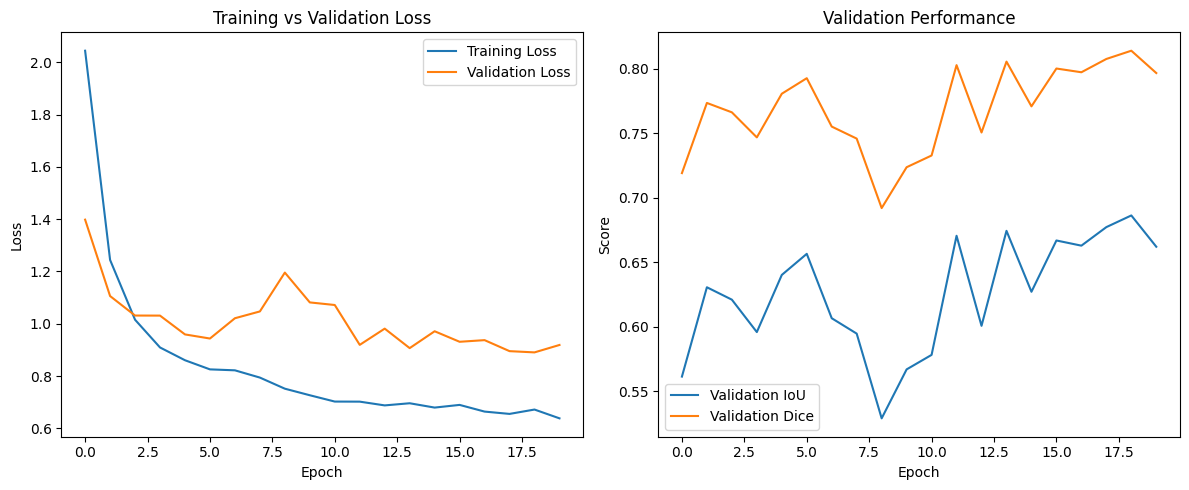

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["val_iou"], label="Validation IoU")
plt.plot(history["val_dice"], label="Validation Dice")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Performance")
plt.legend()

plt.tight_layout()

plt.savefig("results/training_curves.png", dpi=200)
plt.show()